In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

data = pd.read_excel("RegData.xlsx")

print("Dataset shape:", data.shape)
display(data.head())
display(data.dtypes.to_frame(name="data_type"))

Dataset shape: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


,data_type
Date,datetime64[us]
Time,object
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),int64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


In [22]:
sentinel_counts = (
    data.select_dtypes(include="number")
    .eq(-200)
    .sum()
    .sort_values(ascending=False)
)

display(sentinel_counts[sentinel_counts > 0].to_frame(name="count_of_-200"))

data = data.replace(-200, np.nan)

missing_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2),
})

display(missing_summary)

,count_of_-200
NMHC(GT),8443
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
PT08.S1(CO),366
PT08.S2(NMHC),366
C6H6(GT),366
PT08.S3(NOx),366
PT08.S4(NO2),366
PT08.S5(O3),366


,missing_count,missing_percent
Date,0,0.00
Time,0,0.00
CO(GT),1683,17.99
PT08.S1(CO),366,3.91
NMHC(GT),8443,90.23
C6H6(GT),366,3.91
PT08.S2(NMHC),366,3.91
NOx(GT),1639,17.52
PT08.S3(NOx),366,3.91
NO2(GT),1642,17.55


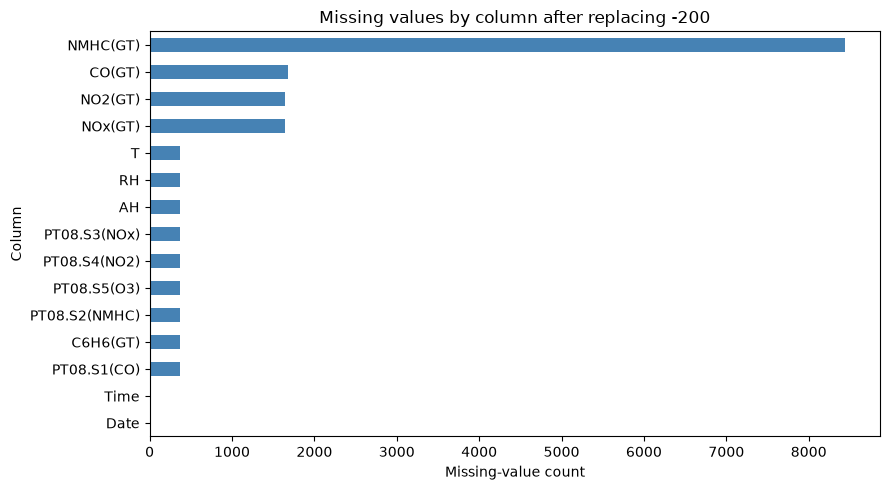

In [23]:
missing_summary["missing_count"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue",
)

plt.title("Missing values by column after replacing -200")
plt.xlabel("Missing-value count")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [24]:
target_column = "CO(GT)"

columns_to_exclude = [
    "Date",
    "Time",
    "NMHC(GT)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
]

required_columns = [target_column, *columns_to_exclude]
missing_columns = [column for column in required_columns if column not in data.columns]

if missing_columns:
    raise ValueError(f"Expected columns not found in the dataset: {missing_columns}")

rows_before = len(data)
data = data.loc[data[target_column].notna()].copy()
rows_removed = rows_before - len(data)

X = data.drop(columns=[target_column, *columns_to_exclude])
y = data[target_column]

print("Target:", target_column)
print("Predictor columns:", X.columns.tolist())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Rows with missing target removed:", rows_removed)

display(X.describe().T.round(2))
display(y.describe().to_frame(name="CO(GT) summary").round(2))

Target: CO(GT)
Predictor columns: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Feature matrix shape: (7674, 8)
Target shape: (7674,)
Rows with missing target removed: 1683


,count,mean,std,min,25%,50%,75%,max
PT08.S1(CO),7344.0,1110.46,218.69,647.25,946.19,1074.75,1245.75,2039.75
PT08.S2(NMHC),7344.0,947.08,265.47,386.75,743.00,918.75,1125.31,2214.00
PT08.S3(NOx),7344.0,826.80,256.65,322.00,649.25,795.00,959.56,2682.75
PT08.S4(NO2),7344.0,1444.63,350.34,551.00,1202.69,1446.50,1672.88,2775.00
PT08.S5(O3),7344.0,1043.39,405.57,221.00,744.44,990.25,1304.50,2522.75
T,7344.0,17.77,8.86,-1.90,11.17,16.92,23.80,44.60
RH,7344.0,49.06,17.45,9.18,35.43,49.33,62.50,88.73
AH,7344.0,0.99,0.40,0.18,0.70,0.96,1.26,2.18


,CO(GT) summary
count,7674.00
mean,2.15
std,1.45
min,0.10
25%,1.10
50%,1.80
75%,2.90
max,11.90


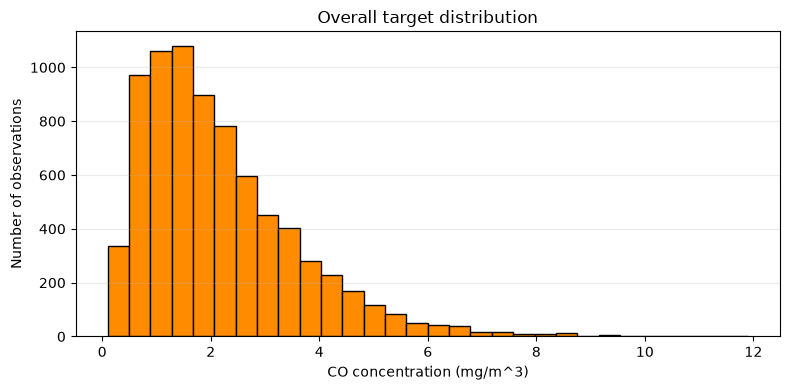

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=30, color="darkorange", edgecolor="black")
ax.set_title("Overall target distribution")
ax.set_xlabel("CO concentration (mg/m^3)")
ax.set_ylabel("Number of observations")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

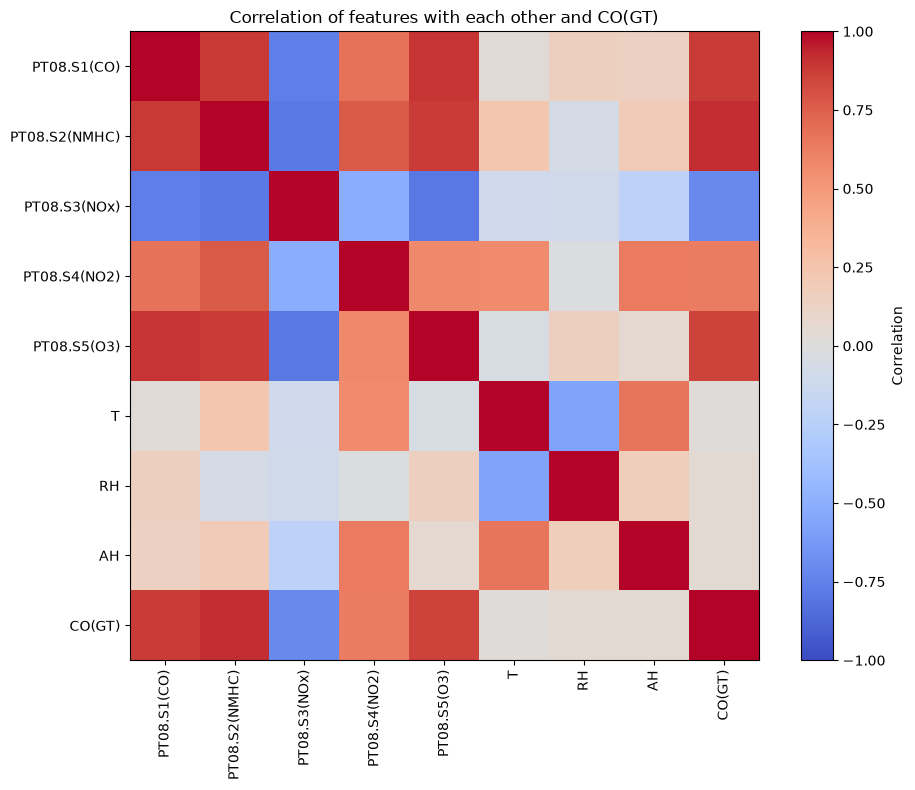

In [26]:
correlation_data = X.copy()
correlation_data[target_column] = y
correlation_matrix = correlation_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns, rotation=90)
ax.set_yticklabels(correlation_matrix.columns)
ax.set_title("Correlation of features with each other and CO(GT)")

fig.colorbar(image, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

In [27]:
random_state = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=random_state,
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Training target rows:", len(y_train))
print("Test target rows:", len(y_test))

assert set(X_train.index).isdisjoint(set(X_test.index))
print("Check passed: training and test rows are disjoint.")

Training feature shape: (6139, 8)
Test feature shape: (1535, 8)
Training target rows: 6139
Test target rows: 1535
Check passed: training and test rows are disjoint.


In [28]:
missing_features = pd.DataFrame({
    "training_missing": X_train.isna().sum(),
    "test_missing": X_test.isna().sum(),
})

display(missing_features)

,training_missing,test_missing
PT08.S1(CO),264,66
PT08.S2(NMHC),264,66
PT08.S3(NOx),264,66
PT08.S4(NO2),264,66
PT08.S5(O3),264,66
T,264,66
RH,264,66
AH,264,66


In [29]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

assert not np.isnan(X_train_imputed).any()
assert not np.isnan(X_test_imputed).any()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

print("Check passed: no missing values remain after imputation.")
print("Check passed: scaled training and test values are finite.")

Check passed: no missing values remain after imputation.
Check passed: scaled training and test values are finite.


In [30]:
scaled_summary = pd.DataFrame(
    {
        "training_mean_after_scaling": X_train_scaled.mean(axis=0),
        "training_std_after_scaling": X_train_scaled.std(axis=0),
    },
    index=X.columns,
).round(4)

display(scaled_summary)

,training_mean_after_scaling,training_std_after_scaling
PT08.S1(CO),-0.0,1.0
PT08.S2(NMHC),-0.0,1.0
PT08.S3(NOx),0.0,1.0
PT08.S4(NO2),-0.0,1.0
PT08.S5(O3),0.0,1.0
T,0.0,1.0
RH,-0.0,1.0
AH,0.0,1.0


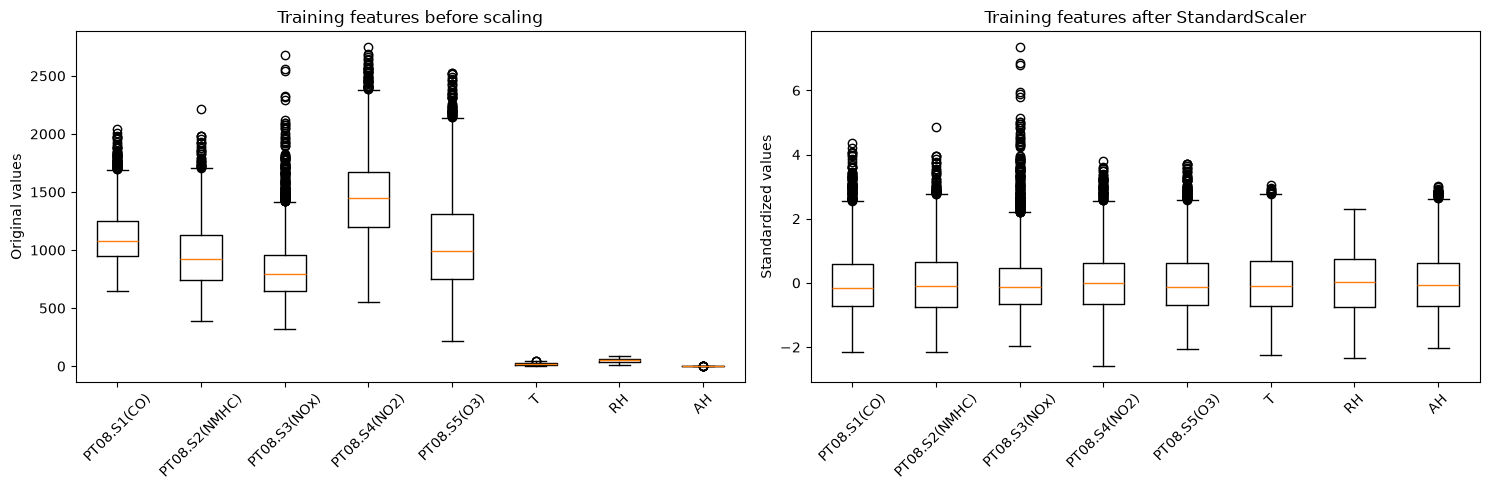

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].boxplot(
    [X_train[column].dropna() for column in X_train.columns],
    tick_labels=X_train.columns,
)
axes[0].set_title("Training features before scaling")
axes[0].set_ylabel("Original values")
axes[0].tick_params(axis="x", rotation=45)

axes[1].boxplot(
    [X_train_scaled[:, index] for index in range(X_train_scaled.shape[1])],
    tick_labels=X.columns,
)
axes[1].set_title("Training features after StandardScaler")
axes[1].set_ylabel("Standardized values")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

In [32]:
models = {
    "Linear Regression": LinearRegression(),
    "Support Vector Regression": SVR(kernel="rbf", C=1.0, epsilon=0.1),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=10,
        random_state=random_state,
    ),
    "MLP Regressor": MLPRegressor(
        hidden_layer_sizes=(100,),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=random_state,
    ),
}

def make_model_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

cross_validation = KFold(
    n_splits=5,
    shuffle=True,
    random_state=random_state,
)

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        make_model_pipeline(model),
        X_train,
        y_train,
        cv=cross_validation,
        scoring={
            "mse": "neg_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
    )

    fold_mse = -scores["test_mse"]
    fold_mae = -scores["test_mae"]
    fold_rmse = np.sqrt(fold_mse)
    fold_r2 = scores["test_r2"]

    cv_results.append({
        "Model": model_name,
        "Mean CV MSE": fold_mse.mean(),
        "CV MSE standard deviation": fold_mse.std(),
        "Mean CV RMSE": fold_rmse.mean(),
        "Mean CV MAE": fold_mae.mean(),
        "Mean CV R2": fold_r2.mean(),
        "CV R2 standard deviation": fold_r2.std(),
    })

cv_table = pd.DataFrame(cv_results).set_index("Model").round(4)

In [33]:
test_results = []
fitted_pipelines = {}
test_predictions = {}

for model_name, model in models.items():
    pipeline = make_model_pipeline(model)

    pipeline.fit(X_train, y_train)
    fitted_pipelines[model_name] = pipeline
    predictions = pipeline.predict(X_test)
    test_predictions[model_name] = predictions

    mse = mean_squared_error(y_test, predictions)

    test_results.append({
        "Model": model_name,
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions),
    })

test_table = (
    pd.DataFrame(test_results)
    .set_index("Model")
    .sort_values("Test RMSE")
    .round(4)
)

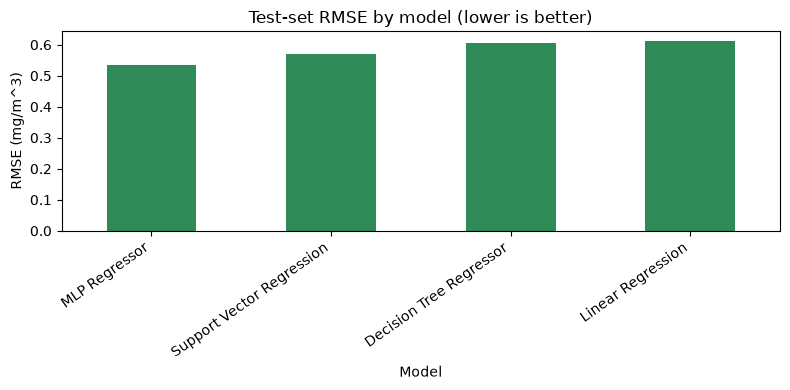

In [34]:
test_table["Test RMSE"].sort_values().plot(
    kind="bar",
    figsize=(8, 4),
    color="seagreen",
)

plt.title("Test-set RMSE by model (lower is better)")
plt.ylabel("RMSE (mg/m^3)")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

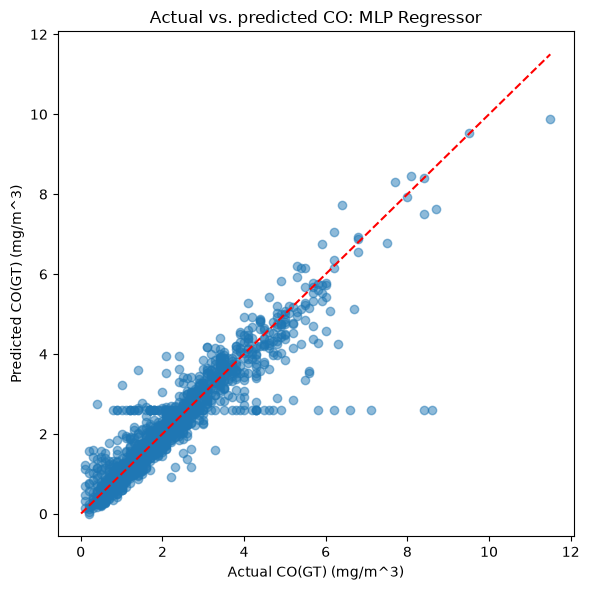

In [35]:
model_to_plot = "MLP Regressor"
predictions = test_predictions[model_to_plot]

minimum_value = min(y_test.min(), predictions.min())
maximum_value = max(y_test.max(), predictions.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.5)
plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    color="red",
    linestyle="--",
)

plt.title(f"Actual vs. predicted CO: {model_to_plot}")
plt.xlabel("Actual CO(GT) (mg/m^3)")
plt.ylabel("Predicted CO(GT) (mg/m^3)")
plt.tight_layout()
plt.show()

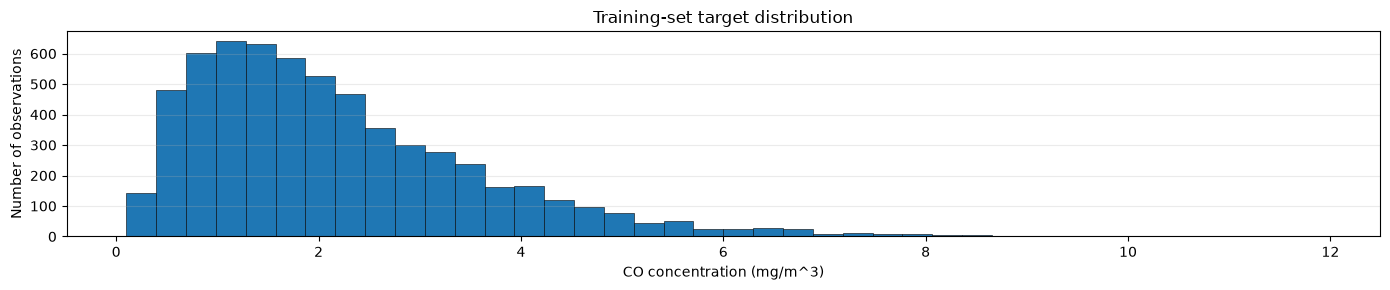

Training rows: 6139
Training target mean: 2.17 | median: 1.8 | min: 0.1 | max: 11.9


In [36]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.hist(y_train, bins=40, color="tab:blue", edgecolor="black", linewidth=0.4)
ax.set_title("Training-set target distribution")
ax.set_xlabel("CO concentration (mg/m^3)")
ax.set_ylabel("Number of observations")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("fig_R1_target_distribution.png", dpi=200)
plt.show()

print("Training rows:", len(y_train))
print("Training target mean:", round(y_train.mean(), 2), "| median:", round(y_train.median(), 2),
      "| min:", y_train.min(), "| max:", y_train.max())

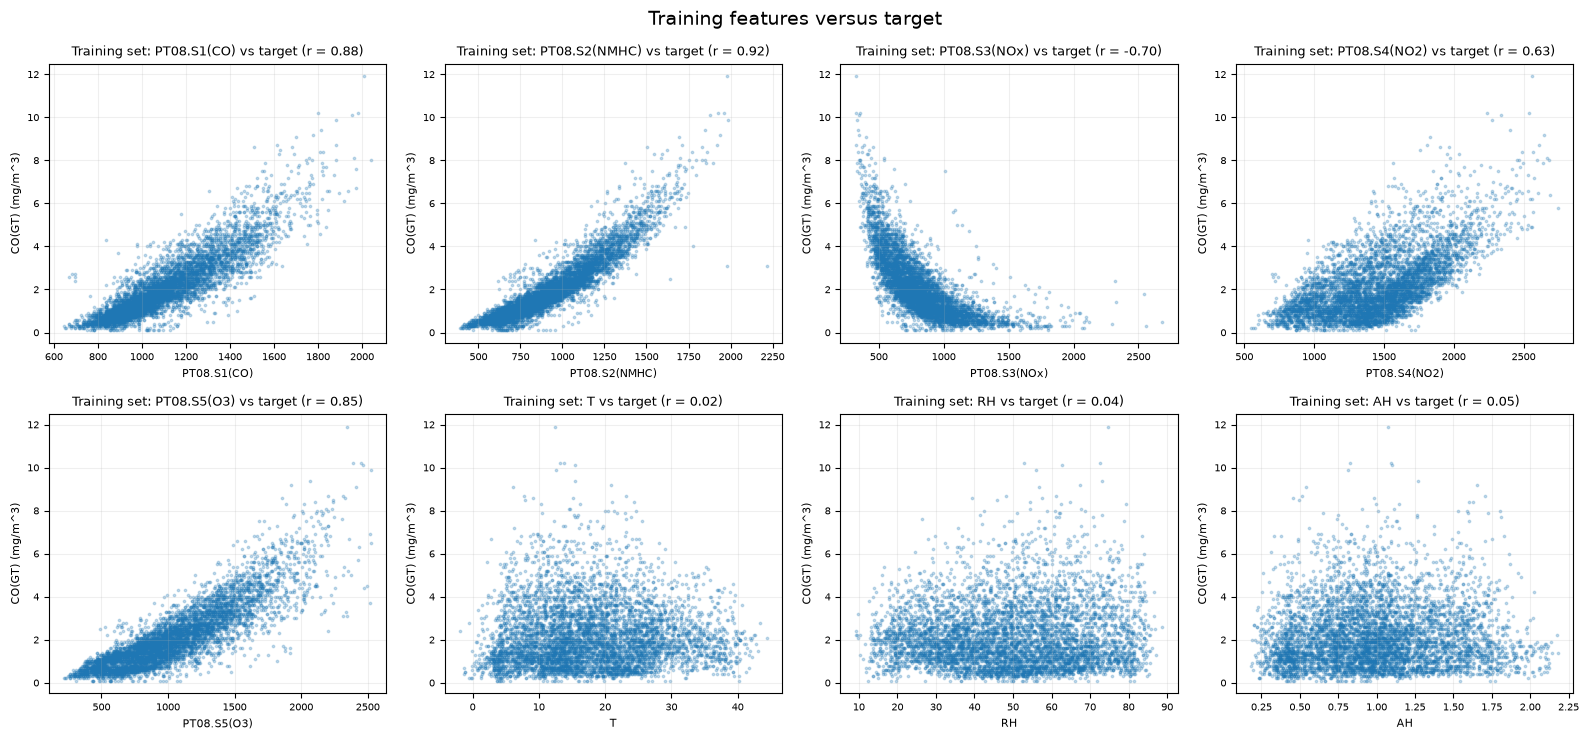

,Correlation with CO(GT)
PT08.S2(NMHC),0.92
PT08.S1(CO),0.88
PT08.S5(O3),0.85
PT08.S4(NO2),0.63
AH,0.05
RH,0.04
T,0.02
PT08.S3(NOx),-0.70


In [37]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
fig.suptitle("Training features versus target", fontsize=14)

for ax, column in zip(axes.ravel(), X_train.columns):
    valid = X_train[column].notna() & y_train.notna()
    ax.scatter(X_train.loc[valid, column], y_train.loc[valid], s=3, alpha=0.25, color="tab:blue")
    r = X_train.loc[valid, column].corr(y_train.loc[valid])
    ax.set_title(f"Training set: {column} vs target (r = {r:.2f})", fontsize=9)
    ax.set_xlabel(column, fontsize=8)
    ax.set_ylabel("CO(GT) (mg/m^3)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.2)

fig.subplots_adjust(top=0.88)
fig.tight_layout()
fig.savefig("fig_R2_features_vs_target.png", dpi=200)
plt.show()

display(X_train.corrwith(y_train).sort_values(ascending=False).round(2).to_frame("Correlation with CO(GT)"))

,Mean CV MSE,CV MSE standard deviation,Mean CV RMSE,Mean CV R2,CV R2 standard deviation,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,,,,,
MLP Regressor,0.2888,0.0513,0.5353,0.8640,0.0203,0.2852,0.5340,0.3062,0.8631
Support Vector Regression,0.3128,0.0673,0.5560,0.8529,0.0273,0.3237,0.5689,0.2961,0.8446
Linear Regression,0.3695,0.0626,0.6057,0.8260,0.0243,0.3753,0.6126,0.3645,0.8198
Decision Tree Regressor,0.4184,0.0623,0.6451,0.8028,0.0236,0.3684,0.6070,0.3636,0.8231


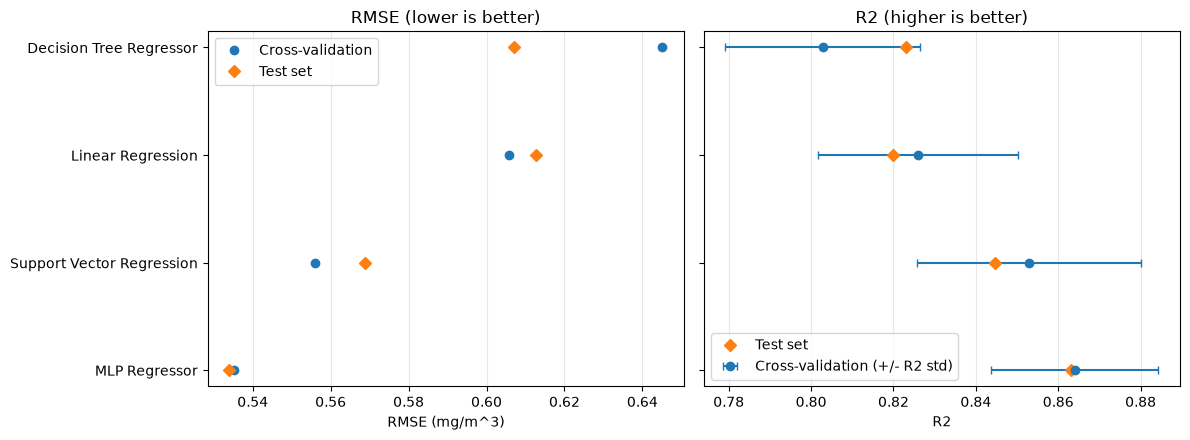

In [38]:
report_cv_table = cv_table[["Mean CV MSE", "CV MSE standard deviation", "Mean CV RMSE", "Mean CV R2", "CV R2 standard deviation"]] \
    .sort_values("Mean CV MSE")
report_table = report_cv_table.join(test_table, how="left")
display(report_table)

plot_data = report_table.sort_values("Mean CV RMSE")
positions = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(
    plot_data["Mean CV RMSE"], positions,
    "o", label="Cross-validation",
)
axes[0].plot(
    plot_data["Test RMSE"], positions,
    "D", label="Test set",
)
axes[0].set_title("RMSE (lower is better)")
axes[0].set_xlabel("RMSE (mg/m^3)")
axes[0].set_yticks(positions)
axes[0].set_yticklabels(plot_data.index)
axes[0].grid(axis="x", alpha=0.3)
axes[0].legend()

axes[1].errorbar(
    plot_data["Mean CV R2"], positions,
    xerr=plot_data["CV R2 standard deviation"],
    fmt="o", capsize=3, label="Cross-validation (+/- R2 std)",
)
axes[1].plot(
    plot_data["Test R2"], positions,
    "D", label="Test set",
)
axes[1].set_title("R2 (higher is better)")
axes[1].set_xlabel("R2")
axes[1].grid(axis="x", alpha=0.3)
axes[1].legend()

fig.tight_layout()
fig.savefig("fig_R4_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

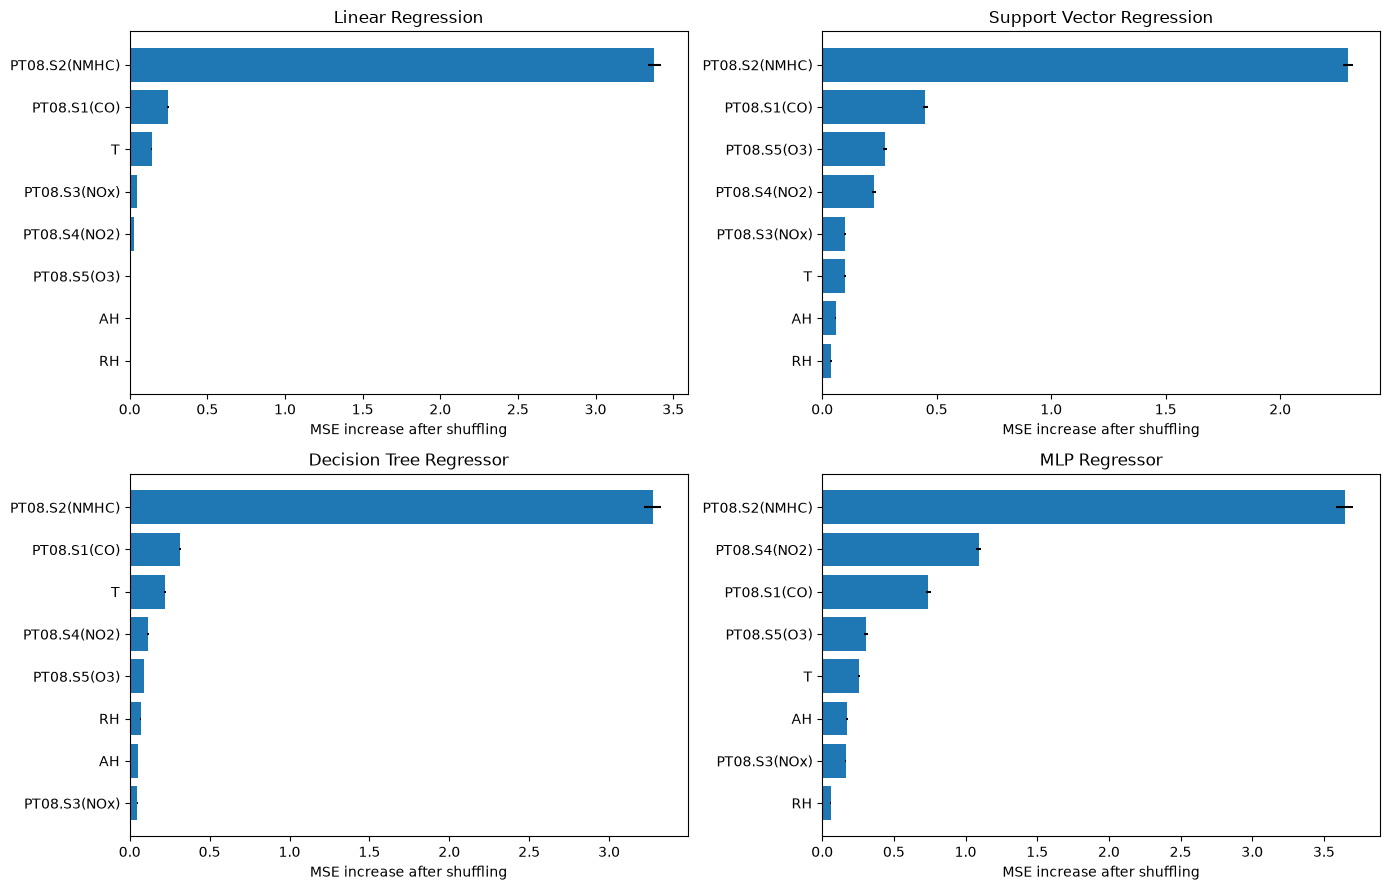

,Linear Regression,Support Vector Regression,Decision Tree Regressor,MLP Regressor
PT08.S2(NMHC),3.3783,2.2966,3.2730,3.6469
PT08.S4(NO2),0.0270,0.2253,0.1128,1.0931
PT08.S1(CO),0.2459,0.4492,0.3153,0.7396
PT08.S5(O3),0.0095,0.2735,0.0895,0.3051
T,0.1412,0.0982,0.2226,0.2549
AH,0.0093,0.0581,0.0515,0.1703
PT08.S3(NOx),0.0471,0.0995,0.0466,0.1632
RH,0.0054,0.0376,0.0684,0.0601


In [39]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
importance_tables = {}

for ax, model_name in zip(axes.ravel(), models):
    result = permutation_importance(
        fitted_pipelines[model_name],
        X_train,
        y_train,
        scoring="neg_mean_squared_error",
        n_repeats=10,
        random_state=random_state,
    )
    importances = pd.DataFrame({
        "mean": result.importances_mean,
        "std": result.importances_std,
    }, index=X_train.columns).sort_values("mean")
    importance_tables[model_name] = importances

    ax.barh(importances.index, importances["mean"], xerr=importances["std"], color="tab:blue")
    ax.set_title(model_name)
    ax.set_xlabel("MSE increase after shuffling")

fig.tight_layout()
fig.savefig("fig_R3_permutation_importance.png", dpi=200)
plt.show()

display(pd.DataFrame({name: table["mean"] for name, table in importance_tables.items()})
        .sort_values("MLP Regressor", ascending=False).round(4))